In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv(
    "data/raw/olist_orders_dataset.csv"
)

print(orders.head())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08

In [10]:
# Number of rows and columns
print(orders.shape)

# Column names
print(orders.columns)

# Data types
print(orders.dtypes)

# Dataset information
orders.info()

# Statistical summary
orders.describe(include="all")

# Missing values
print(orders.isnull().sum())

# Duplicate rows
print(orders.duplicated().sum())

(99441, 8)
Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='object')
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchas

In [11]:
print(orders.shape)
print(orders.head())
print(orders.isnull().sum())

(99441, 8)
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00       

In [12]:
print(orders["order_status"].value_counts())


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [13]:
status_percentage = (
    orders["order_status"].value_counts(normalize=True) * 100
)

print(status_percentage.round(2))

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64


In [14]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

print(orders.dtypes)

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [15]:
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())

Duplicate order IDs: 0


In [16]:
print("Total rows:", len(orders))
print("Unique orders:", orders["order_id"].nunique())

Total rows: 99441
Unique orders: 99441


In [17]:
total_orders = orders["order_id"].nunique()

delivered_orders = (
    orders[orders["order_status"] == "delivered"]["order_id"].nunique()
)

cancelled_orders = (
    orders[orders["order_status"] == "canceled"]["order_id"].nunique()
)

delivery_rate = (delivered_orders / total_orders) * 100

cancellation_rate = (cancelled_orders / total_orders) * 100

print("Total Orders:", total_orders)
print("Delivered Orders:", delivered_orders)
print("Cancelled Orders:", cancelled_orders)
print("Delivery Rate:", round(delivery_rate, 2), "%")
print("Cancellation Rate:", round(cancellation_rate, 2), "%")

Total Orders: 99441
Delivered Orders: 96478
Cancelled Orders: 625
Delivery Rate: 97.02 %
Cancellation Rate: 0.63 %


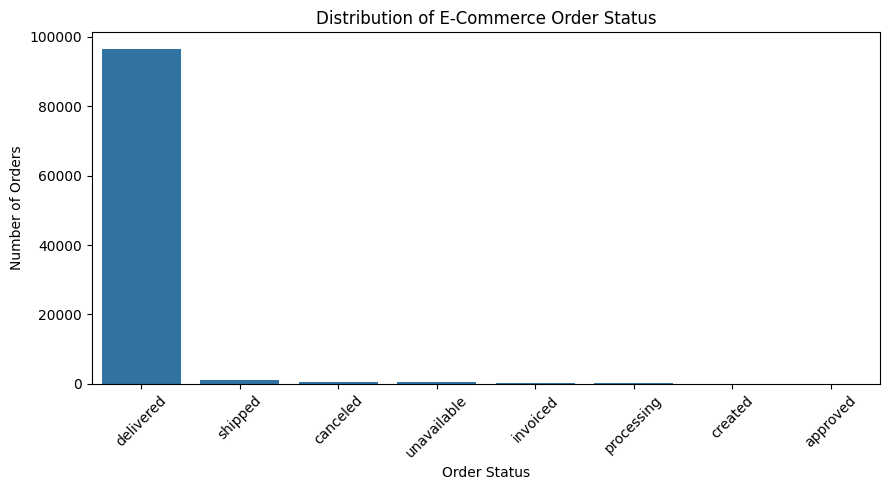

In [18]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=orders,
    x="order_status",
    order=orders["order_status"].value_counts().index
)

plt.title("Distribution of E-Commerce Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [19]:
orders["purchase_month"] = (
    orders["order_purchase_timestamp"].dt.to_period("M")
)

monthly_orders = (
    orders.groupby("purchase_month")["order_id"]
    .nunique()
)

print(monthly_orders)

purchase_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: order_id, dtype: int64


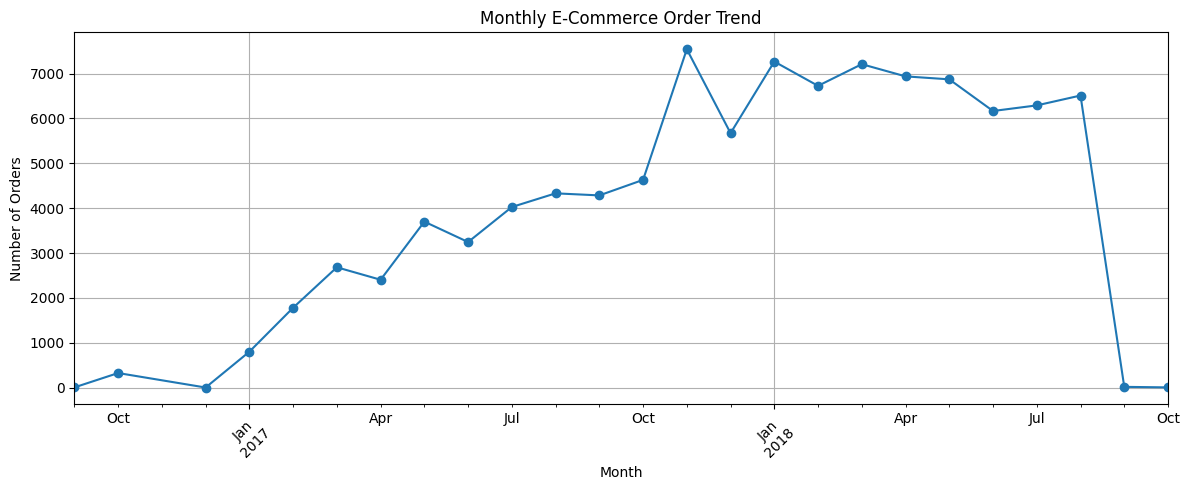

In [20]:
plt.figure(figsize=(12, 5))

monthly_orders.plot(kind="line", marker="o")

plt.title("Monthly E-Commerce Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
status_report = (
    orders["order_status"]
    .value_counts()
    .reset_index()
)

status_report.columns = ["Order Status", "Order Count"]

status_report["Percentage"] = (
    status_report["Order Count"] / len(orders) * 100
)

print(status_report)

  Order Status  Order Count  Percentage
0    delivered        96478   97.020344
1      shipped         1107    1.113223
2     canceled          625    0.628513
3  unavailable          609    0.612423
4     invoiced          314    0.315765
5   processing          301    0.302692
6      created            5    0.005028
7     approved            2    0.002011


In [22]:
delivered = orders[
    orders["order_status"] == "delivered"
].copy()

delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivered["delay_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

print(delivered[["delivery_days", "delay_days"]].describe())

       delivery_days    delay_days
count   96470.000000  96470.000000
mean       12.558217    -11.178126
std         9.546156     10.184354
min         0.533414   -146.016123
25%         6.766204    -16.244065
50%        10.217477    -11.948102
75%        15.720182     -6.389815
max       209.628611    188.975081


In [23]:
total_delivered = len(delivered)

late_orders = (delivered["delay_days"] > 0).sum()

early_or_on_time = (delivered["delay_days"] <= 0).sum()

print("Delivered Orders:", total_delivered)
print("Late Orders:", late_orders)
print("Early / On-time Orders:", early_or_on_time)

print(
    "Late Delivery Percentage:",
    round((late_orders / total_delivered) * 100, 2),
    "%"
)

Delivered Orders: 96478
Late Orders: 7826
Early / On-time Orders: 88644
Late Delivery Percentage: 8.11 %


In [24]:
valid_delivery = delivered.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

valid_total = len(valid_delivery)

late_orders = (valid_delivery["delay_days"] > 0).sum()

late_percentage = (late_orders / valid_total) * 100

print("Valid delivery records:", valid_total)
print("Late orders:", late_orders)
print("Accurate late delivery rate:", round(late_percentage, 2), "%")

Valid delivery records: 96470
Late orders: 7826
Accurate late delivery rate: 8.11 %


In [25]:
print(
    valid_delivery[
        ["order_id", "delivery_days", "delay_days"]
    ]
    .sort_values(by="delay_days", ascending=False)
    .head(5)
)

                               order_id  delivery_days  delay_days
55619  1b3190b2dfa9d789e1f14c05b647a14a     208.351759  188.975081
19590  ca07593549f1816d26a572e06dc1eab6     209.628611  181.608785
11399  47b40429ed8cce3aee9199792275433f     191.463542  175.869109
81401  2fe324febf907e3ea3f2aa9650869fa5     189.863160  167.708414
89130  285ab9426d6982034523a855f55a885e     194.633611  166.583380


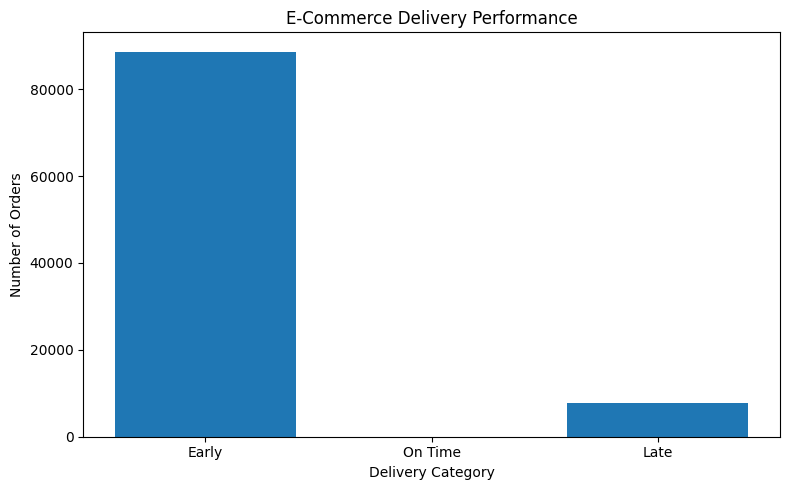

In [26]:
delivery_categories = [
    "Early",
    "On Time",
    "Late"
]

delivery_counts = [
    (valid_delivery["delay_days"] < 0).sum(),
    (valid_delivery["delay_days"] == 0).sum(),
    (valid_delivery["delay_days"] > 0).sum()
]

plt.figure(figsize=(8, 5))

plt.bar(delivery_categories, delivery_counts)

plt.title("E-Commerce Delivery Performance")
plt.xlabel("Delivery Category")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

In [27]:
extreme_order_id = "1b3190b2dfa9d789e1f14c05b647a14a"

print(
    orders[orders["order_id"] == extreme_order_id].T
)

                                                          55619
order_id                       1b3190b2dfa9d789e1f14c05b647a14a
customer_id                    d306426abe5fca15e54b645e4462dc7b
order_status                                          delivered
order_purchase_timestamp                    2018-02-23 14:57:35
order_approved_at                           2018-02-23 15:16:14
order_delivered_carrier_date                2018-02-26 18:49:07
order_delivered_customer_date               2018-09-19 23:24:07
order_estimated_delivery_date               2018-03-15 00:00:00
purchase_month                                          2018-02


In [28]:
payments = pd.read_csv(
    "data/raw/olist_order_payments_dataset.csv"
)

print(payments.head())
print(payments.shape)
print(payments.info())
print(payments.isnull().sum())

                           order_id  payment_sequential payment_type  \
0  b81ef226f3fe1789b1e8b2acac839d17                   1  credit_card   
1  a9810da82917af2d9aefd1278f1dcfa0                   1  credit_card   
2  25e8ea4e93396b6fa0d3dd708e76c1bd                   1  credit_card   
3  ba78997921bbcdc1373bb41e913ab953                   1  credit_card   
4  42fdf880ba16b47b59251dd489d4441a                   1  credit_card   

   payment_installments  payment_value  
0                     8          99.33  
1                     1          24.39  
2                     1          65.71  
3                     8         107.78  
4                     2         128.45  
(103886, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null 

In [29]:
print(payments["payment_type"].value_counts())
print("-------------------------")

print(payments["payment_value"].describe())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64
-------------------------
count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64


In [30]:
payment_summary = (
    payments.groupby("payment_type")
    .agg(
        transactions=("payment_type", "count"),
        total_value=("payment_value", "sum"),
        average_value=("payment_value", "mean")
    )
    .sort_values(by="total_value", ascending=False)
)

payment_summary["percentage"] = (
    payment_summary["total_value"]
    / payment_summary["total_value"].sum()
) * 100

print(payment_summary.round(2))

              transactions  total_value  average_value  percentage
payment_type                                                      
credit_card          76795  12542084.19         163.32       78.34
boleto               19784   2869361.27         145.03       17.92
voucher               5775    379436.87          65.70        2.37
debit_card            1529    217989.79         142.57        1.36
not_defined              3         0.00           0.00        0.00


In [31]:
total_payment_value = payments["payment_value"].sum()

print("Total recorded payment value:", round(total_payment_value, 2))

Total recorded payment value: 16008872.12


In [32]:
payment_per_order = (
    payments.groupby("order_id")
    .agg(
        payment_records=("payment_sequential", "count"),
        total_order_payment=("payment_value", "sum")
    )
)

print(payment_per_order.head(10))

print(
    "Orders with multiple payment records:",
    (payment_per_order["payment_records"] > 1).sum()
)

                                  payment_records  total_order_payment
order_id                                                              
00010242fe8c5a6d1ba2dd792cb16214                1                72.19
00018f77f2f0320c557190d7a144bdd3                1               259.83
000229ec398224ef6ca0657da4fc703e                1               216.87
00024acbcdf0a6daa1e931b038114c75                1                25.78
00042b26cf59d7ce69dfabb4e55b4fd9                1               218.04
00048cc3ae777c65dbb7d2a0634bc1ea                1                34.59
00054e8431b9d7675808bcb819fb4a32                1                31.75
000576fe39319847cbb9d288c5617fa6                1               880.75
0005a1a1728c9d785b8e2b08b904576c                1               157.60
0005f50442cb953dcd1d21e1fb923495                1                65.39
Orders with multiple payment records: 2961


In [33]:
payment_per_order = (
    payments.groupby("order_id")
    .agg(
        total_payment=("payment_value", "sum"),
        payment_records=("payment_sequential", "count")
    )
    .reset_index()
)

print(payment_per_order.head())
print(payment_per_order.shape)

                           order_id  total_payment  payment_records
0  00010242fe8c5a6d1ba2dd792cb16214          72.19                1
1  00018f77f2f0320c557190d7a144bdd3         259.83                1
2  000229ec398224ef6ca0657da4fc703e         216.87                1
3  00024acbcdf0a6daa1e931b038114c75          25.78                1
4  00042b26cf59d7ce69dfabb4e55b4fd9         218.04                1
(99440, 3)


In [34]:
orders_payments = pd.merge(
    orders,
    payment_per_order,
    on="order_id",
    how="left"
)

print(orders_payments.head())
print(orders_payments.shape)

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp   order_approved_at  \
0    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37 2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49 2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06 2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39 2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08-07 15

In [35]:
orders_payments["purchase_month"] = (
    orders_payments["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_payment = (
    orders_payments.groupby("purchase_month")["total_payment"]
    .sum()
)

print(monthly_payment)

purchase_month
2016-09        252.24
2016-10      59090.48
2016-12         19.62
2017-01     138488.04
2017-02     291908.01
2017-03     449863.60
2017-04     417788.03
2017-05     592918.82
2017-06     511276.38
2017-07     592382.92
2017-08     674396.32
2017-09     727762.45
2017-10     779677.88
2017-11    1194882.80
2017-12     878401.48
2018-01    1115004.18
2018-02     992463.34
2018-03    1159652.12
2018-04    1160785.48
2018-05    1153982.15
2018-06    1023880.50
2018-07    1066540.75
2018-08    1022425.32
2018-09       4439.54
2018-10        589.67
Freq: M, Name: total_payment, dtype: float64


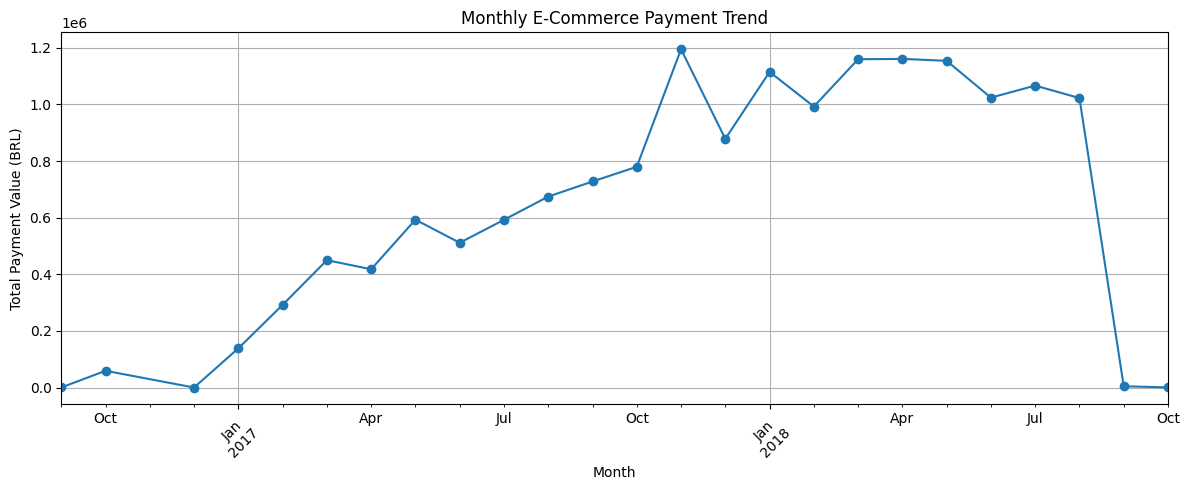

In [36]:
plt.figure(figsize=(12, 5))

monthly_payment.plot(kind="line", marker="o")

plt.title("Monthly E-Commerce Payment Trend")
plt.xlabel("Month")
plt.ylabel("Total Payment Value (BRL)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

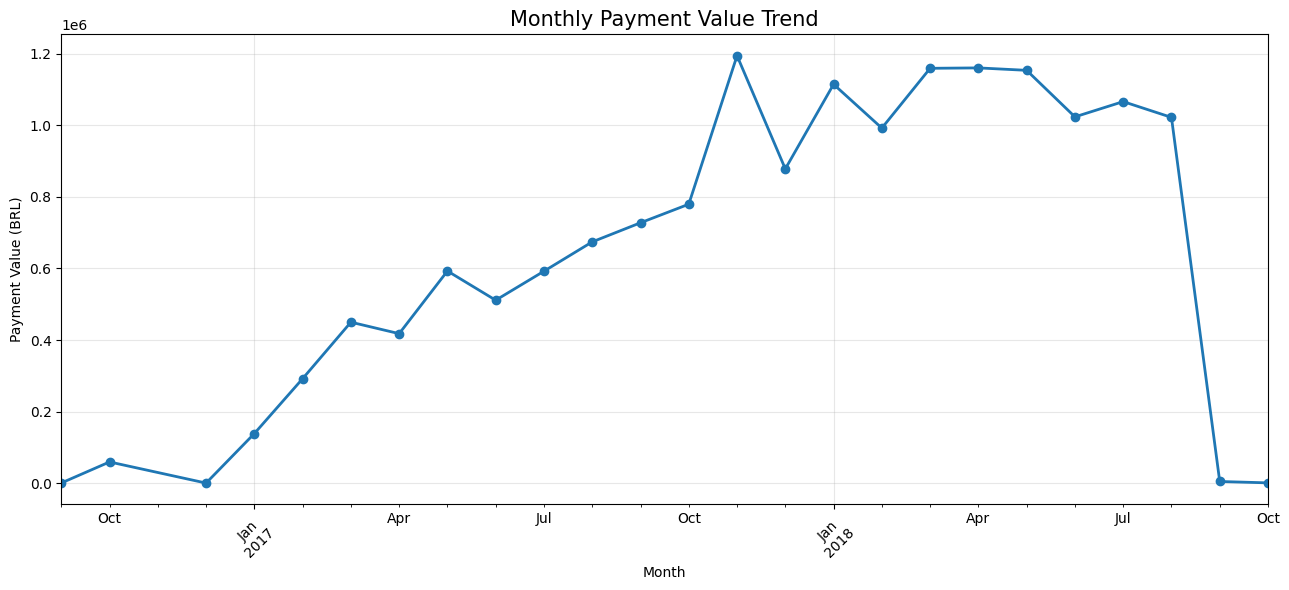

In [37]:
plt.figure(figsize=(13, 6))

monthly_payment.plot(
    kind="line",
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Payment Value Trend",
    fontsize=15
)

plt.xlabel("Month")
plt.ylabel("Payment Value (BRL)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
total_orders = orders_payments["order_id"].nunique()

paid_orders = orders_payments[
    orders_payments["total_payment"].notna()
]["order_id"].nunique()

average_order_value = (
    orders_payments["total_payment"].sum() / paid_orders
)

print("Total Orders:", total_orders)
print("Orders with Payment Records:", paid_orders)

print(
    "Average Payment per Paid Order:",
    round(average_order_value, 2),
    "BRL"
)

Total Orders: 99441
Orders with Payment Records: 99440
Average Payment per Paid Order: 160.99 BRL


In [39]:
status_payment = (
    orders_payments.groupby("order_status")
    .agg(
        order_count=("order_id", "nunique"),
        total_payment=("total_payment", "sum")
    )
    .sort_values(
        by="total_payment",
        ascending=False
    )
)

print(status_payment.round(2))

              order_count  total_payment
order_status                            
delivered           96478    15422461.77
shipped              1107      177213.96
canceled              625      143255.60
unavailable           609      126479.51
processing            301       69394.11
invoiced              314       69137.99
created                 5         688.10
approved                2         241.08


In [40]:
unpaid_orders = orders_payments[
    orders_payments["total_payment"].isna()
]

print(unpaid_orders[
    ["order_id", "order_status"]
])

                               order_id order_status
30710  bfbd0f9bdef84302105ad712db648a6c    delivered


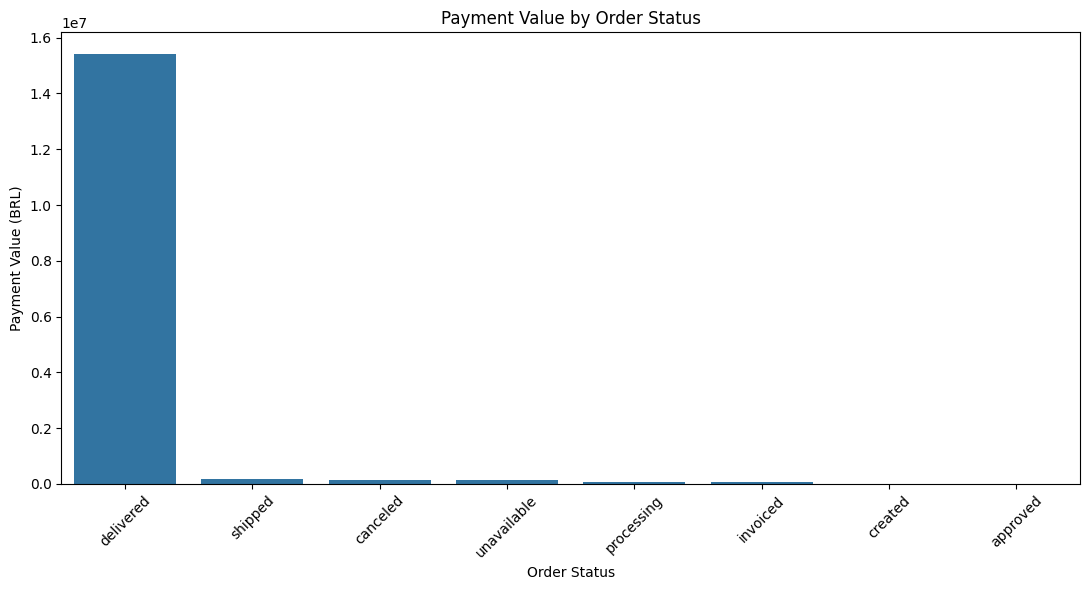

In [41]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=status_payment.reset_index(),
    x="order_status",
    y="total_payment"
)

plt.title("Payment Value by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Payment Value (BRL)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [42]:
order_items = pd.read_csv(
    "data/raw/olist_order_items_dataset.csv"
)

products = pd.read_csv(
    "data/raw/olist_products_dataset.csv"
)

print("Order Items:", order_items.shape)
print("Products:", products.shape)

print(order_items.head())
print(products.head())

Order Items: (112650, 7)
Products: (32951, 9)
                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value  
0  2017-09-19 09:45:35   58.90          13.29  
1  2017-05-03 11:05:13  239.90          19.93  
2  2018-01-18 14:48:30  199.00          17.87 

In [43]:
print(order_items.isnull().sum())
print(products.isnull().sum())

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [44]:
print(order_items.columns.tolist())
print(products.columns.tolist())

['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


In [45]:
# Check duplicate records
print("Duplicate order items:", order_items.duplicated().sum())
print("Duplicate product IDs:", products["product_id"].duplicated().sum())

# Check missing product categories
print("Missing categories:", products["product_category_name"].isnull().sum())

# Fill missing category names
products["product_category_name"] = (
    products["product_category_name"].fillna("unknown")
)

# Check missing product dimensions
print(products[
    ["product_weight_g", "product_length_cm",
     "product_height_cm", "product_width_cm"]
].isnull().sum())

Duplicate order items: 0
Duplicate product IDs: 0
Missing categories: 610
product_weight_g     2
product_length_cm    2
product_height_cm    2
product_width_cm     2
dtype: int64


In [46]:
# Merge order items with product information
product_sales = pd.merge(
    order_items,
    products,
    on="product_id",
    how="left"
)

print("Merged Dataset Shape:", product_sales.shape)
product_sales.head()

Merged Dataset Shape: (112650, 15)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0


In [47]:
category_sales = (
    product_sales.groupby("product_category_name")
    .agg(
        total_orders=("order_id", "nunique"),
        total_items=("product_id", "count"),
        total_revenue=("price", "sum"),
        average_price=("price", "mean")
    )
    .sort_values(by="total_revenue", ascending=False)
)

category_sales.head(10)

,total_orders,total_items,total_revenue,average_price
product_category_name,,,,
beleza_saude,8836,9670,1258681.34,130.163531
relogios_presentes,5624,5991,1205005.68,201.135984
cama_mesa_banho,9417,11115,1036988.68,93.296327
esporte_lazer,7720,8641,988048.97,114.344285
informatica_acessorios,6689,7827,911954.32,116.513903
moveis_decoracao,6449,8334,729762.49,87.564494
cool_stuff,3632,3796,635290.85,167.357969
utilidades_domesticas,5884,6964,632248.66,90.788148
automotivo,3897,4235,592720.11,139.957523


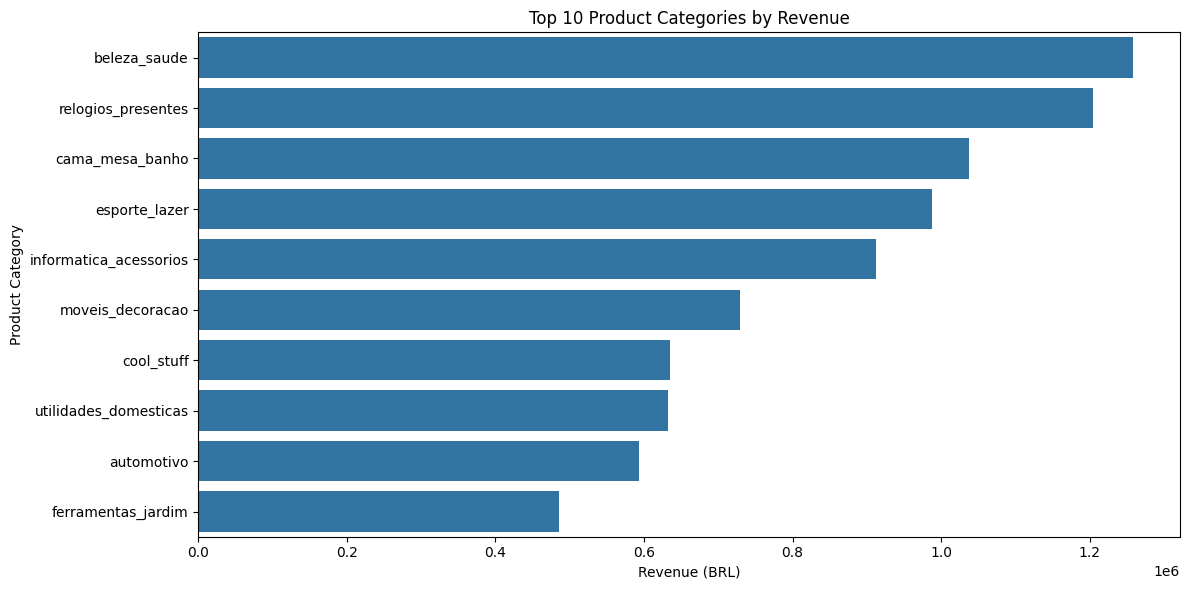

In [48]:
top_categories = category_sales.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x="total_revenue",
    y="product_category_name"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [49]:
# Top 10 categories by number of items sold

top_selling_categories = (
    category_sales
    .sort_values(by="total_items", ascending=False)
    .head(10)
    .reset_index()
)

print(top_selling_categories[
    ["product_category_name", "total_items", "total_revenue"]
])

    product_category_name  total_items  total_revenue
0         cama_mesa_banho        11115     1036988.68
1            beleza_saude         9670     1258681.34
2           esporte_lazer         8641      988048.97
3        moveis_decoracao         8334      729762.49
4  informatica_acessorios         7827      911954.32
5   utilidades_domesticas         6964      632248.66
6      relogios_presentes         5991     1205005.68
7               telefonia         4545      323667.53
8      ferramentas_jardim         4347      485256.46
9              automotivo         4235      592720.11


In [50]:
# Shipping cost analysis by category

shipping_analysis = (
    product_sales.groupby("product_category_name")
    .agg(
        average_product_price=("price", "mean"),
        average_shipping_cost=("freight_value", "mean"),
        total_shipping_cost=("freight_value", "sum")
    )
    .sort_values(by="average_shipping_cost", ascending=False)
)

shipping_analysis.head(10)

,average_product_price,average_shipping_cost,total_shipping_cost
product_category_name,,,
pcs,1098.340542,48.454680,9836.30
eletrodomesticos_2,476.124958,44.538571,10600.18
moveis_colchao_e_estofado,114.949474,42.906842,1630.46
moveis_cozinha_area_de_servico_jantar_e_jardim,164.869644,42.702598,11999.43
moveis_quarto,183.750275,42.497523,4632.23
moveis_escritorio,162.011059,40.551124,68571.95
portateis_casa_forno_e_cafe,624.285658,36.156053,2747.86
moveis_sala,137.011054,35.722008,17968.17
sinalizacao_e_seguranca,108.086583,32.702613,6507.82


In [51]:
shipping_analysis["shipping_percentage"] = (
    shipping_analysis["average_shipping_cost"] /
    shipping_analysis["average_product_price"]
) * 100

shipping_analysis.sort_values(
    by="shipping_percentage",
    ascending=False
).head(10)

,average_product_price,average_shipping_cost,total_shipping_cost,shipping_percentage
product_category_name,,,,
casa_conforto_2,25.342333,13.677000,410.31,53.968985
flores,33.637576,14.814242,488.87,44.040755
moveis_colchao_e_estofado,114.949474,42.906842,1630.46,37.326697
artigos_de_natal,57.521699,21.106536,3229.30,36.693172
fraldas_higiene,40.194615,14.709744,573.68,36.596304
cds_dvds_musicais,52.142857,16.070714,224.99,30.820548
sinalizacao_e_seguranca,108.086583,32.702613,6507.82,30.255941
alimentos_bebidas,54.602446,16.215791,4507.99,29.697921
eletronicos,57.913531,16.833509,46578.32,29.066626


In [52]:
category_order_share = (
    product_sales.groupby("product_category_name")
    .agg(
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

total_unique_orders = product_sales["order_id"].nunique()

category_order_share["order_percentage"] = (
    category_order_share["total_orders"] /
    total_unique_orders
) * 100

category_order_share = category_order_share.sort_values(
    by="total_orders",
    ascending=False
)

category_order_share.head(10)

,product_category_name,total_orders,order_percentage
13,cama_mesa_banho,9417,9.544321
11,beleza_saude,8836,8.955466
32,esporte_lazer,7720,7.824377
44,informatica_acessorios,6689,6.779438
54,moveis_decoracao,6449,6.536193
73,utilidades_domesticas,5884,5.963554
66,relogios_presentes,5624,5.700039
70,telefonia,4199,4.255772
8,automotivo,3897,3.949689
12,brinquedos,3886,3.938540


In [53]:
category_comparison = category_sales.copy()

category_comparison["revenue_per_item"] = (
    category_comparison["total_revenue"] /
    category_comparison["total_items"]
)

category_comparison = category_comparison.sort_values(
    by="revenue_per_item",
    ascending=False
)

category_comparison.head(10)

,total_orders,total_items,total_revenue,average_price,revenue_per_item
product_category_name,,,,,
pcs,181,203,222963.13,1098.340542,1098.340542
portateis_casa_forno_e_cafe,75,76,47445.71,624.285658,624.285658
eletrodomesticos_2,234,238,113317.74,476.124958,476.124958
agro_industria_e_comercio,182,212,72530.47,342.124858,342.124858
instrumentos_musicais,628,680,191498.88,281.616000,281.616000
eletroportateis,630,679,190648.58,280.778468,280.778468
portateis_cozinha_e_preparadores_de_alimentos,14,15,3968.53,264.568667,264.568667
telefonia_fixa,217,264,59583.00,225.693182,225.693182
construcao_ferramentas_seguranca,167,194,40544.52,208.992371,208.992371


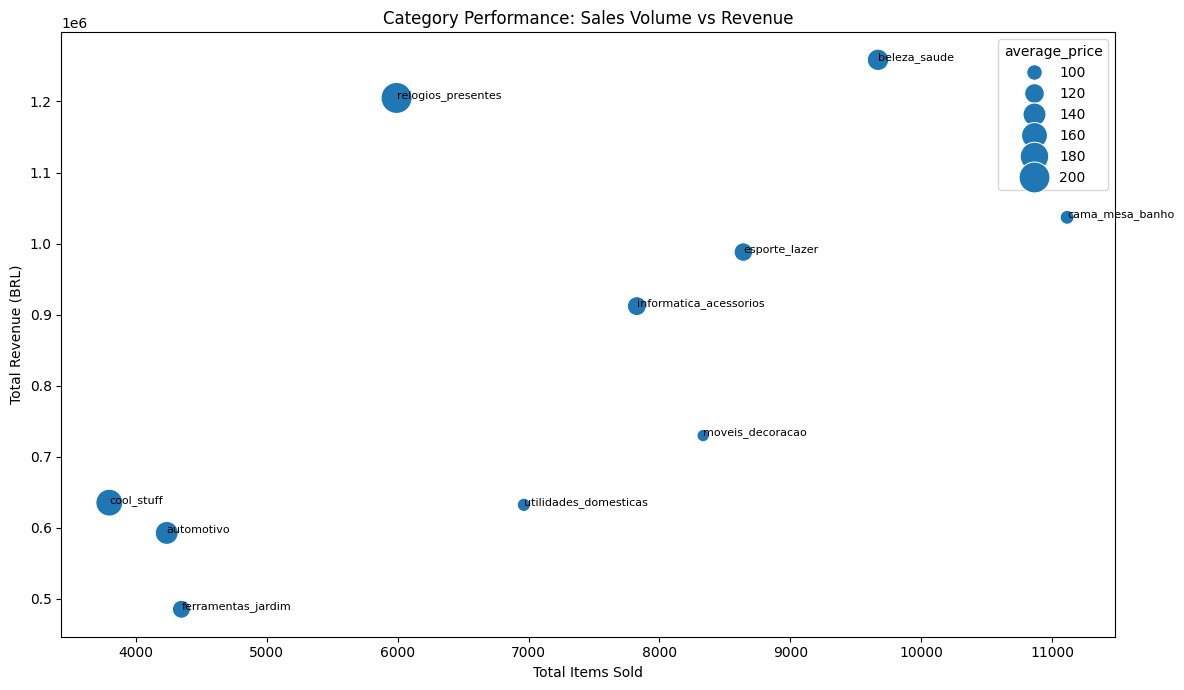

In [54]:
top_10 = category_sales.head(10).reset_index()

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=top_10,
    x="total_items",
    y="total_revenue",
    size="average_price",
    sizes=(80, 500),
    legend=True
)

for _, row in top_10.iterrows():
    plt.annotate(
        row["product_category_name"],
        (row["total_items"], row["total_revenue"]),
        fontsize=8
    )

plt.title("Category Performance: Sales Volume vs Revenue")
plt.xlabel("Total Items Sold")
plt.ylabel("Total Revenue (BRL)")
plt.tight_layout()
plt.show()

In [55]:
# Export product and category analysis results

category_sales.to_csv(
    "data/processed/category_sales_analysis.csv"
)

category_order_share.to_csv(
    "data/processed/category_order_share.csv",
    index=False
)

shipping_analysis.to_csv(
    "data/processed/category_shipping_analysis.csv"
)

category_comparison.to_csv(
    "data/processed/category_price_analysis.csv"
)

print("Product & Category Analysis exported successfully!")

Product & Category Analysis exported successfully!


In [56]:
customers = pd.read_csv(
    "data/raw/olist_customers_dataset.csv"
)

print("Dataset Shape:", customers.shape)

print("\nFirst 5 Records:")
display(customers.head())

print("\nColumn Names:")
print(customers.columns.tolist())

print("\nMissing Values:")
print(customers.isnull().sum())

print("\nDuplicate Records:")
print(customers.duplicated().sum())

Dataset Shape: (99441, 5)

First 5 Records:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



Column Names:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Missing Values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Duplicate Records:
0


In [57]:
print(
    "Total Customer Records:",
    customers["customer_id"].nunique()
)

print(
    "Unique Actual Customers:",
    customers["customer_unique_id"].nunique()
)

print(
    "Unique Customer States:",
    customers["customer_state"].nunique()
)

print("\nCustomers by State:")
print(
    customers["customer_state"]
    .value_counts()
    .head(10)
)

Total Customer Records: 99441
Unique Actual Customers: 96096
Unique Customer States: 27

Customers by State:
customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64


In [58]:
# Merge customers with orders

customer_orders = pd.merge(
    customers,
    orders,
    on="customer_id",
    how="inner"
)

print("Merged Dataset Shape:", customer_orders.shape)

display(customer_orders.head())

Merged Dataset Shape: (99441, 13)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_month
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05,2017-05
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06,2018-01
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13,2018-05
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10,2018-03
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15,2018-07


In [59]:
# Count orders per actual customer

customer_order_counts = (
    customer_orders.groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

# Identify repeat customers

repeat_customers = customer_order_counts[
    customer_order_counts["total_orders"] > 1
]

one_time_customers = customer_order_counts[
    customer_order_counts["total_orders"] == 1
]

print("Total Unique Customers:",
      len(customer_order_counts))

print("Repeat Customers:",
      len(repeat_customers))

print("One-time Customers:",
      len(one_time_customers))

print("Repeat Customer Percentage:",
      round(len(repeat_customers) /
            len(customer_order_counts) * 100, 2), "%")

Total Unique Customers: 96096
Repeat Customers: 2997
One-time Customers: 93099
Repeat Customer Percentage: 3.12 %


In [60]:
customer_payment_data = pd.merge(
    customer_orders,
    payment_per_order,
    on="order_id",
    how="left"
)

customer_metrics = (
    customer_payment_data
    .groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_spent=("total_payment", "sum"),
        paid_orders=("total_payment", "count")
    )
    .reset_index()
)

customer_metrics["average_order_value"] = (
    customer_metrics["total_spent"] /
    customer_metrics["paid_orders"].replace(0, np.nan)
)

display(customer_metrics.head())

,customer_unique_id,total_orders,total_spent,paid_orders,average_order_value
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,1,27.19
2,0000f46a3911fa3c0805444483337064,1,86.22,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,1,196.89


In [61]:
print("Total Customers:", len(customer_metrics))

print(
    "Average Customer Spending: R$",
    round(customer_metrics["total_spent"].mean(), 2)
)

print(
    "Median Customer Spending: R$",
    round(customer_metrics["total_spent"].median(), 2)
)

print(
    "Highest Customer Spending: R$",
    round(customer_metrics["total_spent"].max(), 2)
)


Total Customers: 96096
Average Customer Spending: R$ 166.59
Median Customer Spending: R$ 108.0
Highest Customer Spending: R$ 13664.08


In [62]:
def segment_customer(spending):
    if spending >= 500:
        return "High-value"
    elif spending >= 150:
        return "Regular"
    else:
        return "Occasional"


customer_metrics["customer_segment"] = (
    customer_metrics["total_spent"].apply(segment_customer)
)

segment_summary = (
    customer_metrics.groupby("customer_segment")
    .agg(
        total_customers=("customer_unique_id", "count"),
        average_spending=("total_spent", "mean"),
        average_orders=("total_orders", "mean"),
        total_revenue=("total_spent", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

segment_summary["customer_percentage"] = (
    segment_summary["total_customers"] /
    len(customer_metrics) * 100
)

display(segment_summary.round(2))

,total_customers,average_spending,average_orders,total_revenue,customer_percentage
customer_segment,,,,,
Regular,28143,241.64,1.07,6800387.97,29.29
Occasional,63464,79.32,1.01,5033930.89,66.04
High-value,4489,929.95,1.13,4174553.26,4.67


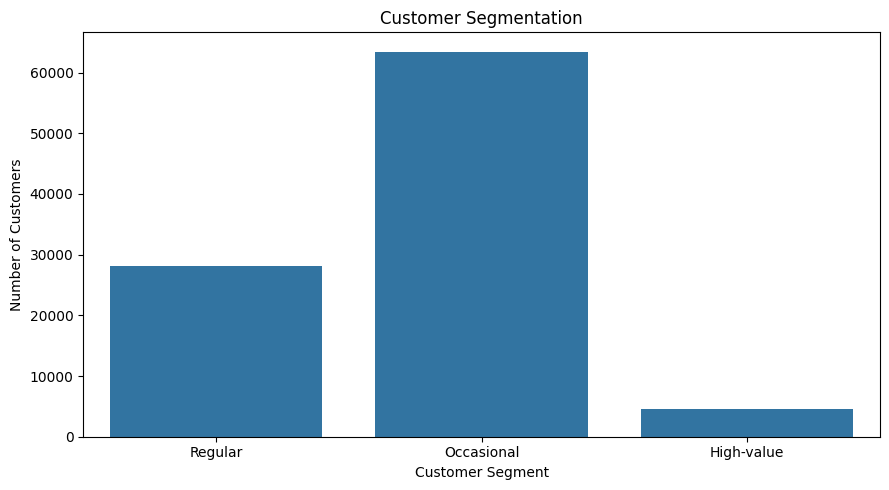

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    x=segment_summary.index,
    y=segment_summary["total_customers"]
)

plt.title("Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [65]:
customer_state_metrics = (
    customer_payment_data
    .groupby(["customer_state", "customer_unique_id"])
    .agg(
        total_orders=("order_id", "nunique"),
        total_spent=("total_payment", "sum")
    )
    .reset_index()
)

In [66]:
state_analysis = (
    customer_state_metrics
    .groupby("customer_state")
    .agg(
        unique_customers=("customer_unique_id", "nunique"),
        total_orders=("total_orders", "sum"),
        total_revenue=("total_spent", "sum"),
        average_customer_spending=("total_spent", "mean")
    )
    .sort_values("total_revenue", ascending=False)
)

state_analysis["customer_percentage"] = (
    state_analysis["unique_customers"] /
    state_analysis["unique_customers"].sum() * 100
)

display(state_analysis.round(2))

,unique_customers,total_orders,total_revenue,average_customer_spending,customer_percentage
customer_state,,,,,
SP,40302,41746,5998226.96,148.83,41.92
RJ,12384,12852,2144379.69,173.16,12.88
MG,11259,11635,1872257.26,166.29,11.71
RS,5277,5466,890898.54,168.83,5.49
PR,4882,5045,811156.38,166.15,5.08
SC,3534,3637,623086.43,176.31,3.68
BA,3277,3380,616645.82,188.17,3.41
DF,2075,2140,355141.08,171.15,2.16
GO,1952,2020,350092.31,179.35,2.03


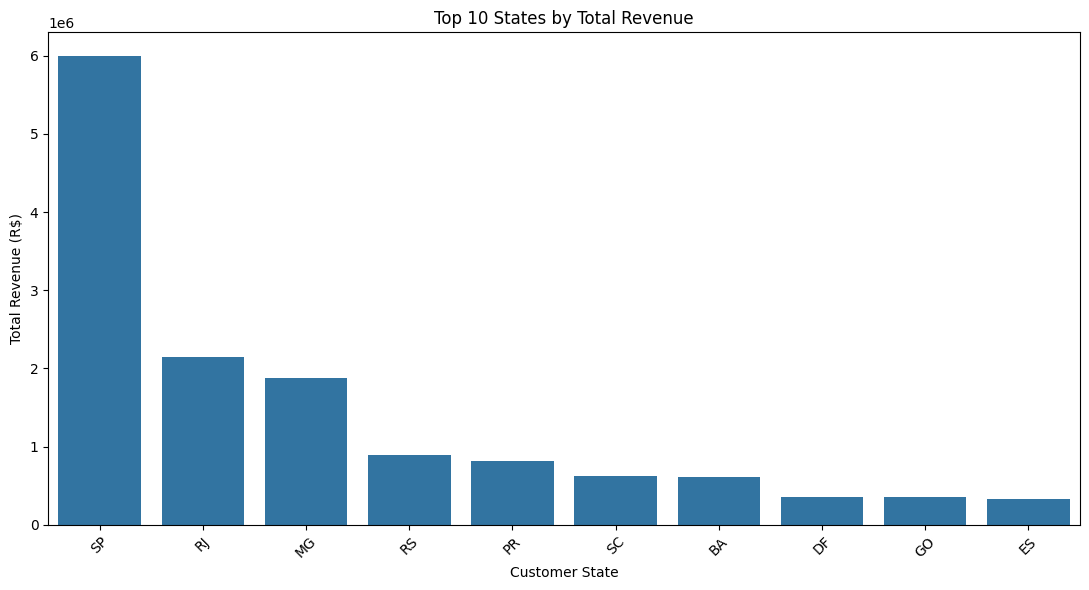

In [67]:
top_10_states = state_analysis.head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_10_states.index,
    y=top_10_states["total_revenue"]
)

plt.title("Top 10 States by Total Revenue")
plt.xlabel("Customer State")
plt.ylabel("Total Revenue (R$)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [68]:
reviews = pd.read_csv(
    "data/raw/olist_order_reviews_dataset.csv"
)

sellers = pd.read_csv(
    "data/raw/olist_sellers_dataset.csv"
)

print("Reviews Dataset Shape:", reviews.shape)
print("Sellers Dataset Shape:", sellers.shape)

print("\nReview Columns:")
print(reviews.columns.tolist())

print("\nSeller Columns:")
print(sellers.columns.tolist())

Reviews Dataset Shape: (99224, 7)
Sellers Dataset Shape: (3095, 4)

Review Columns:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

Seller Columns:
['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']


In [69]:
print("Review Missing Values:")
print(reviews.isnull().sum())

print("\nDuplicate Review IDs:")
print(reviews["review_id"].duplicated().sum())

print("\nReview Score Distribution:")
print(reviews["review_score"].value_counts().sort_index())

print("\nSeller Missing Values:")
print(sellers.isnull().sum())

print("\nDuplicate Seller IDs:")
print(sellers["seller_id"].duplicated().sum())

Review Missing Values:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Duplicate Review IDs:
814

Review Score Distribution:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

Seller Missing Values:
seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

Duplicate Seller IDs:
0


In [70]:
duplicate_reviews = reviews[
    reviews.duplicated(subset="review_id", keep=False)
].sort_values("review_id")

print("Total rows with duplicate review IDs:",
      len(duplicate_reviews))

print("Exact duplicate rows:",
      reviews.duplicated().sum())

print("\nDuplicate review ID examples:")
display(duplicate_reviews.head(10))

Total rows with duplicate review IDs: 1603
Exact duplicate rows: 0

Duplicate review ID examples:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [71]:
duplicate_review_check = (
    duplicate_reviews.groupby("review_id")
    .agg(
        order_count=("order_id", "nunique"),
        score_count=("review_score", "nunique"),
        record_count=("order_id", "count")
    )
)

print("Duplicate IDs linked to multiple orders:",
      (duplicate_review_check["order_count"] > 1).sum())

print("Duplicate IDs with different scores:",
      (duplicate_review_check["score_count"] > 1).sum())

display(duplicate_review_check.head(10))

Duplicate IDs linked to multiple orders: 789
Duplicate IDs with different scores: 0


,order_count,score_count,record_count
review_id,,,
00130cbe1f9d422698c812ed8ded1919,2,1,2
0115633a9c298b6a98bcbe4eee75345f,2,1,2
0174caf0ee5964646040cd94e15ac95e,2,1,2
017808d29fd1f942d97e50184dfb4c13,2,1,2
0254bd905dc677a6078990aad3331a36,2,1,2
0288d42bef3dfe36930740c9588a570f,2,1,2
02aa7f5f75e964e3c7efa59a1f515281,2,1,2
034528cb00b6bc981847acafbdf2ae0b,2,1,2
03a6a25db577d0689440933055111897,2,1,2


In [72]:
print("Average Review Score:",
      round(reviews["review_score"].mean(), 2))

print("Median Review Score:",
      reviews["review_score"].median())

print("Positive Reviews (4 and 5 stars):",
      round(
          reviews["review_score"].isin([4, 5]).mean() * 100,
          2
      ), "%")

print("Negative Reviews (1 and 2 stars):",
      round(
          reviews["review_score"].isin([1, 2]).mean() * 100,
          2
      ), "%")

Average Review Score: 4.09
Median Review Score: 5.0
Positive Reviews (4 and 5 stars): 77.07 %
Negative Reviews (1 and 2 stars): 14.69 %


In [73]:
print("Total Review Records:", len(reviews))

print("Unique Review IDs:",
      reviews["review_id"].nunique())

print("Unique Orders Reviewed:",
      reviews["order_id"].nunique())

print("Exact Duplicate Rows:",
      reviews.duplicated().sum())

print("Duplicate Order IDs:",
      reviews["order_id"].duplicated().sum())

print("\nReview IDs linked to multiple orders:",
      (duplicate_review_check["order_count"] > 1).sum())

Total Review Records: 99224
Unique Review IDs: 98410
Unique Orders Reviewed: 98673
Exact Duplicate Rows: 0
Duplicate Order IDs: 551

Review IDs linked to multiple orders: 789


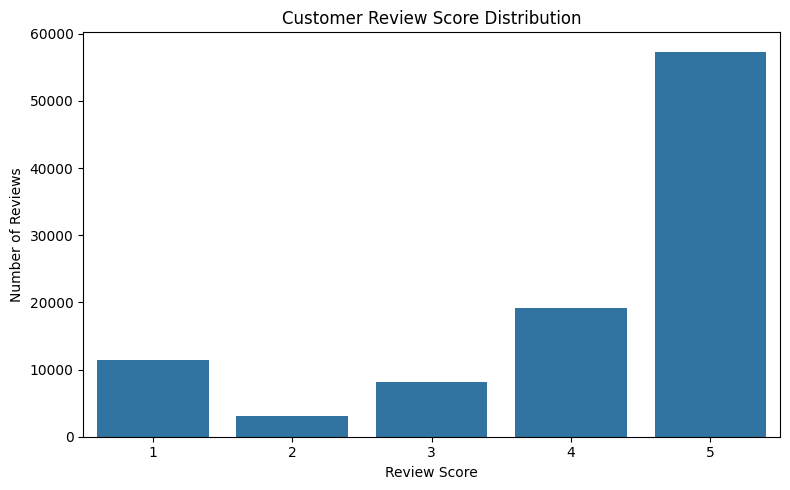

In [74]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=reviews,
    x="review_score"
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

In [75]:
review_orders = pd.merge(
    reviews,
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

review_items = pd.merge(
    review_orders,
    order_items[["order_id", "product_id"]],
    on="order_id",
    how="inner"
)

review_products = pd.merge(
    review_items,
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

print("Review Orders Shape:", review_orders.shape)
print("Review Items Shape:", review_items.shape)
print("Review Products Shape:", review_products.shape)

display(review_products.head())

Review Orders Shape: (99224, 8)
Review Items Shape: (112372, 9)
Review Products Shape: (112372, 10)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,order_status,product_id,product_category_name
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59,delivered,fd25ab760bfbba13c198fa3b4f1a0cd3,esporte_lazer
1,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59,delivered,fd25ab760bfbba13c198fa3b4f1a0cd3,esporte_lazer
2,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13,delivered,be0dbdc3d67d55727a65d4cd696ca73c,informatica_acessorios
3,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24,delivered,d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios
4,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06,delivered,52c80cedd4e90108bf4fa6a206ef6b03,ferramentas_jardim


In [76]:
category_reviews = (
    review_products
    .groupby("product_category_name")
    .agg(
        total_orders=("order_id", "nunique"),
        total_review_records=("review_id", "count"),
        average_review_score=("review_score", "mean"),
        negative_reviews=(
            "review_score",
            lambda x: (x <= 2).sum()
        )
    )
)

category_reviews["negative_review_percentage"] = (
    category_reviews["negative_reviews"] /
    category_reviews["total_review_records"] * 100
)

category_reviews = category_reviews.sort_values(
    "average_review_score"
)

display(category_reviews.head(15).round(2))

,total_orders,total_review_records,average_review_score,negative_reviews,negative_review_percentage
product_category_name,,,,,
seguros_e_servicos,2,2,2.50,1,50.00
fraldas_higiene,27,39,3.26,10,25.64
portateis_cozinha_e_preparadores_de_alimentos,14,15,3.27,5,33.33
pc_gamer,8,9,3.33,3,33.33
moveis_escritorio,1263,1687,3.49,440,26.08
casa_conforto_2,23,27,3.63,7,25.93
fashion_roupa_masculina,111,131,3.64,37,28.24
telefonia_fixa,214,262,3.68,67,25.57
artigos_de_festas,39,43,3.77,10,23.26


In [77]:
order_review_scores = (
    reviews.groupby("order_id")
    .agg(
        order_review_score=("review_score", "mean"),
        review_records=("review_score", "count")
    )
    .reset_index()
)

print("Orders with reviews:", order_review_scores["order_id"].nunique())
display(order_review_scores.head())

Orders with reviews: 98673


,order_id,order_review_score,review_records
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,1
1,00018f77f2f0320c557190d7a144bdd3,4.0,1
2,000229ec398224ef6ca0657da4fc703e,5.0,1
3,00024acbcdf0a6daa1e931b038114c75,4.0,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0,1


In [79]:
order_category = (
    order_items[["order_id", "product_id"]]
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
    .drop_duplicates(["order_id", "product_category_name"])
)

category_review_data = order_category.merge(
    order_review_scores,
    on="order_id",
    how="inner"
)

category_reviews = (
    category_review_data
    .groupby("product_category_name")
    .agg(
        total_orders=("order_id", "nunique"),
        average_review_score=("order_review_score", "mean"),
        negative_orders=(
            "order_review_score",
            lambda x: (x <= 2).sum()
        )
    )
)

category_reviews["negative_order_percentage"] = (
    category_reviews["negative_orders"] /
    category_reviews["total_orders"] * 100
)

category_reviews = category_reviews.sort_values(
    "average_review_score"
)

display(category_reviews.head(15).round(2))

,total_orders,average_review_score,negative_orders,negative_order_percentage
product_category_name,,,,
seguros_e_servicos,2,2.50,1,50.00
pc_gamer,8,3.12,3,37.50
portateis_cozinha_e_preparadores_de_alimentos,14,3.43,4,28.57
moveis_escritorio,1263,3.62,286,22.64
fashion_roupa_masculina,111,3.70,29,26.13
fashion_roupa_feminina,39,3.73,8,20.51
fraldas_higiene,27,3.74,5,18.52
moveis_colchao_e_estofado,38,3.82,8,21.05
casa_conforto_2,23,3.83,5,21.74


In [80]:
category_reviews.to_csv(
    "data/processed/category_review_analysis.csv"
)

print("Category review analysis saved successfully!")

Category review analysis saved successfully!


In [81]:
# Create unique seller-order combinations
seller_orders = (
    order_items[["seller_id", "order_id"]]
    .drop_duplicates()
)

# Add seller details
seller_orders = seller_orders.merge(
    sellers,
    on="seller_id",
    how="left"
)

# Add order and delivery details
seller_orders = seller_orders.merge(
    orders[
        [
            "order_id",
            "order_status",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
    ],
    on="order_id",
    how="left"
)

# Add order-level review scores
seller_orders = seller_orders.merge(
    order_review_scores[
        ["order_id", "order_review_score"]
    ],
    on="order_id",
    how="left"
)

print("Seller Orders Shape:", seller_orders.shape)
print("Unique Sellers:", seller_orders["seller_id"].nunique())
print("Unique Orders:", seller_orders["order_id"].nunique())

display(seller_orders.head())

Seller Orders Shape: (100010, 10)
Unique Sellers: 3095
Unique Orders: 98666


,seller_id,order_id,seller_zip_code_prefix,seller_city,seller_state,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,order_review_score
0,48436dade18ac8b2bce089ec2a041202,00010242fe8c5a6d1ba2dd792cb16214,27277,volta redonda,SP,delivered,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,5.0
1,dd7ddc04e1b6c2c614352b383efe2d36,00018f77f2f0320c557190d7a144bdd3,3471,sao paulo,SP,delivered,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,4.0
2,5b51032eddd242adc84c38acab88f23d,000229ec398224ef6ca0657da4fc703e,37564,borda da mata,MG,delivered,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,5.0
3,9d7a1d34a5052409006425275ba1c2b4,00024acbcdf0a6daa1e931b038114c75,14403,franca,SP,delivered,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,4.0
4,df560393f3a51e74553ab94004ba5c87,00042b26cf59d7ce69dfabb4e55b4fd9,87900,loanda,PR,delivered,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,5.0


In [82]:
seller_order_counts = (
    seller_orders
    .groupby(["seller_id", "seller_city", "seller_state"])
    .agg(
        total_orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("total_orders", ascending=False)
)

display(seller_order_counts.head(15))

,seller_id,seller_city,seller_state,total_orders
1235,6560211a19b47992c3666cc44a7e94c0,sao paulo,SP,1854
881,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806
2481,cc419e0650a3c5ba77189a1882b7556a,santo andre,SP,1706
368,1f50f920176fa81dab994f9023523100,sao jose do rio preto,SP,1404
2643,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314
1824,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1287
1505,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160
2836,ea8482cd71df3c1969d7b9473ff13abc,sao paulo,SP,1146
857,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132
731,3d871de0142ce09b7081e2b9d1733cb1,campo limpo paulista,SP,1080


In [83]:
seller_ratings = (
    seller_orders
    .groupby(["seller_id", "seller_city", "seller_state"])
    .agg(
        total_orders=("order_id", "nunique"),
        average_review_score=("order_review_score", "mean"),
        rated_orders=("order_review_score", "count")
    )
    .reset_index()
)

seller_ratings = seller_ratings.sort_values(
    "average_review_score",
    ascending=False
)

display(seller_ratings.head(15).round(2))

,seller_id,seller_city,seller_state,total_orders,average_review_score,rated_orders
3072,feb793c88d836c3a75efa4b5a3465d70,sao paulo,SP,1,5.0,1
4,003554e2dce176b5555353e4f3555ac8,goiania,GO,1,5.0,1
2519,cf6f6bc4df3999b9c6440f124fb2f687,sao paulo,SP,1,5.0,1
1160,5e25c632f9db6cfb8bc100421c2737b6,chapeco,SC,1,5.0,1
1159,5e106d93b717c2682b9383da480364a1,santa terezinha de itaipu,PR,1,5.0,1
1157,5e063e85d44b0f5c3e6ec3131103a57e,sao paulo,SP,1,5.0,1
1179,6025c79c035c3d772133b8b8238463b2,pinhais/pr,PR,2,5.0,2
55,04ee0ec01589969663ba5967c0e0bdc0,lajeado,RS,1,5.0,1
50,04843805947f0fc584fc1969b6e50fe7,ivoti,RS,1,5.0,1
49,044668ccd5316b12a7cf0d54a156e3e9,osasco,SP,3,5.0,3


In [84]:
reliable_seller_ratings = seller_ratings[
    seller_ratings["rated_orders"] >= 50
].copy()

reliable_seller_ratings = reliable_seller_ratings.sort_values(
    ["average_review_score", "rated_orders"],
    ascending=[False, False]
)

display(reliable_seller_ratings.head(15).round(2))

,seller_id,seller_city,seller_state,total_orders,average_review_score,rated_orders
2531,d13e50eaa47b4cbe9eb81465865d8cfc,santo andre,SP,67,4.82,67
2629,d9bd94811c3338dceb4181f3dbc0c73e,sao paulo,SP,54,4.80,54
2580,d566c37fa119d5e66c4e9052e83ee4ea,sao paulo,SP,65,4.69,64
647,376a891762bbdecbc02b4b6adec3fdda,goiania,GO,57,4.67,57
201,116ccb1a1604bc88e4d234a8c23f33de,sao bernardo do campo,SP,61,4.64,61
322,1bb2bdb95f4841f1bba2c0d2cd83d3c9,sao paulo,SP,81,4.64,80
100,080199a181c46c657dc5aa235411be3b,osasco,SP,79,4.62,78
2077,ac3508719a1d8f5b7614b798f70af136,canoas,RS,103,4.60,101
1123,5b925e1d006e9476d738aa200751b73b,sao paulo,SP,63,4.60,63
2802,e882b2a25a10b9c057cc49695f222c19,teresopolis,RJ,57,4.58,57


In [85]:
# Convert delivery columns to datetime
seller_orders["order_delivered_customer_date"] = pd.to_datetime(
    seller_orders["order_delivered_customer_date"]
)

seller_orders["order_estimated_delivery_date"] = pd.to_datetime(
    seller_orders["order_estimated_delivery_date"]
)

# Calculate delivery delay in days
seller_orders["delivery_delay_days"] = (
    seller_orders["order_delivered_customer_date"] -
    seller_orders["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

# Classify delivery performance
seller_orders["delivery_status"] = "Not delivered"

seller_orders.loc[
    seller_orders["delivery_delay_days"] > 0,
    "delivery_status"
] = "Late"

seller_orders.loc[
    seller_orders["delivery_delay_days"] <= 0,
    "delivery_status"
] = "On-time/Early"

print("Delivery Status Distribution:")
print(seller_orders["delivery_status"].value_counts())

print("\nDelivery Delay Statistics:")
display(
    seller_orders["delivery_delay_days"].describe().round(2)
)

Delivery Status Distribution:
delivery_status
On-time/Early    89972
Late              7845
Not delivered     2193
Name: count, dtype: int64

Delivery Delay Statistics:


count    97817.00
mean       -11.25
std         10.18
min       -146.02
25%        -16.28
50%        -12.02
75%         -6.43
max        188.98
Name: delivery_delay_days, dtype: float64

In [86]:
seller_delivery = (
    seller_orders[seller_orders["delivery_delay_days"].notna()]
    .groupby(["seller_id", "seller_city", "seller_state"])
    .agg(
        total_delivered_orders=("order_id", "nunique"),
        late_orders=(
            "delivery_status",
            lambda x: (x == "Late").sum()
        ),
        average_delay_days=("delivery_delay_days", "mean")
    )
    .reset_index()
)

seller_delivery["late_delivery_percentage"] = (
    seller_delivery["late_orders"] /
    seller_delivery["total_delivered_orders"] * 100
)

seller_delivery = seller_delivery.sort_values(
    "late_delivery_percentage",
    ascending=False
)

display(seller_delivery.head(15).round(2))

,seller_id,seller_city,seller_state,total_delivered_orders,late_orders,average_delay_days,late_delivery_percentage
2850,f524ad65d7e0f1daab730ef2d2e86196,soledade,RS,1,1,3.84,100.0
951,51a04a8a6bdcb23deccc82b0b80742cf,braganca paulista,SP,1,1,7.82,100.0
2859,f5fea3ffed6c2e889bab72705557c63a,rio de janeiro,RJ,1,1,1.70,100.0
649,391bbd13b6452244774beff1824006ed,campinas,SP,1,1,24.03,100.0
288,19484c79cef6c062cb177aa4ef2fcc3c,valinhos,SP,1,1,3.50,100.0
1835,9c57bc60cfad5ee62d35d3f1ce4593a1,curitiba,PR,1,1,14.60,100.0
1827,9bf11dfc0bec77e5a23028043c3c5a8f,contagem,MG,1,1,12.49,100.0
382,20f0aeea30bc3b8c4420be8ced4226c0,santa barbara d'oeste,SP,1,1,13.52,100.0
2184,bc8c8d665ec4664d286be0d521722b19,sao paulo,SP,1,1,4.66,100.0
1865,9ef932e837d8b7f392c0bfee9d359dc2,ibitinga,SP,1,1,9.00,100.0


In [87]:
reliable_seller_delivery = seller_delivery[
    seller_delivery["total_delivered_orders"] >= 50
].copy()

reliable_seller_delivery = reliable_seller_delivery.sort_values(
    "late_delivery_percentage",
    ascending=False
)

display(reliable_seller_delivery.head(15).round(2))

,seller_id,seller_city,seller_state,total_delivered_orders,late_orders,average_delay_days,late_delivery_percentage
1000,54965bbe3e4f07ae045b90b0b8541f52,foz do iguacu,PR,73,22,-2.87,30.14
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,sao paulo,SP,96,25,-3.68,26.04
2211,beadbee30901a7f61d031b6b686095ad,guarulhos,SP,64,16,-8.75,25.00
79,06a2c3af7b3aee5d69171b0e14f0ee87,sao luis,MA,389,90,-10.66,23.14
2365,cac4c8e7b1ca6252d8f20b2fc1a2e4af,indaiatuba,SP,74,17,-6.08,22.97
323,1ca7077d890b907f89be8c954a02686a,santana de parnaiba,SP,108,24,-5.96,22.22
1141,6039e27294dc75811c0d8a39069f52c0,osasco,SP,63,14,-6.62,22.22
1336,712e6ed8aa4aa1fa65dab41fed5737e4,videira,SC,77,17,-8.42,22.08
2720,ea566164622c6b439516ab18062c42cd,sao paulo,SP,50,11,-7.39,22.00
2435,d13e50eaa47b4cbe9eb81465865d8cfc,santo andre,SP,66,14,-3.84,21.21


In [88]:
seller_performance = pd.merge(
    seller_ratings,
    seller_delivery,
    on=["seller_id", "seller_city", "seller_state"],
    how="inner"
)

# Focus on sellers with sufficient data for both metrics
seller_performance = seller_performance[
    (seller_performance["rated_orders"] >= 50) &
    (seller_performance["total_delivered_orders"] >= 50)
].copy()

seller_performance = seller_performance.sort_values(
    "late_delivery_percentage",
    ascending=False
)

display(
    seller_performance[
        [
            "seller_id",
            "seller_city",
            "seller_state",
            "total_orders",
            "average_review_score",
            "rated_orders",
            "total_delivered_orders",
            "late_orders",
            "late_delivery_percentage",
            "average_delay_days"
        ]
    ].head(15).round(2)
)

,seller_id,seller_city,seller_state,total_orders,average_review_score,rated_orders,total_delivered_orders,late_orders,late_delivery_percentage,average_delay_days
2706,54965bbe3e4f07ae045b90b0b8541f52,foz do iguacu,PR,78,3.00,74,73,22,30.14,-2.87
2661,a49928bcdf77c55c6d6e05e09a9b4ca5,sao paulo,SP,98,3.01,98,96,25,26.04,-3.68
2134,beadbee30901a7f61d031b6b686095ad,guarulhos,SP,64,3.91,64,64,16,25.00,-8.75
2055,06a2c3af7b3aee5d69171b0e14f0ee87,sao luis,MA,392,3.99,388,389,90,23.14,-10.66
2486,cac4c8e7b1ca6252d8f20b2fc1a2e4af,indaiatuba,SP,75,3.55,74,74,17,22.97,-6.08
2377,6039e27294dc75811c0d8a39069f52c0,osasco,SP,64,3.69,64,63,14,22.22,-6.62
2855,1ca7077d890b907f89be8c954a02686a,santana de parnaiba,SP,115,2.33,114,108,24,22.22,-5.96
2568,712e6ed8aa4aa1fa65dab41fed5737e4,videira,SC,79,3.38,78,77,17,22.08,-8.42
2304,ea566164622c6b439516ab18062c42cd,sao paulo,SP,50,3.78,50,50,11,22.00,-7.39
542,d13e50eaa47b4cbe9eb81465865d8cfc,santo andre,SP,67,4.82,67,66,14,21.21,-3.84


In [89]:
seller_order_counts.to_csv(
    "data/processed/seller_order_analysis.csv",
    index=False
)

seller_ratings.to_csv(
    "data/processed/seller_rating_analysis.csv",
    index=False
)

seller_delivery.to_csv(
    "data/processed/seller_delivery_analysis.csv",
    index=False
)

seller_performance.to_csv(
    "data/processed/seller_performance_analysis.csv",
    index=False
)

print("All seller analysis files saved successfully!")

All seller analysis files saved successfully!
